# Random Forest Regression

Predict hourly electricity demand using Random Forest regression
and compare performance against Ridge and naïve baselines.

## Objectives

- Explore decision trees and ensemble learning.
- Evaluate nonlinear forecasting performance.
- Investigate improvements in peak demand prediction.

In [2]:
import warnings

warnings.filterwarnings("ignore")

## Imports and Data Preparation

In [3]:
from src.build_features import build_features

features = build_features()

In [4]:
features.columns

Index(['target_kw', 'hour', 'day_of_week', 'month', 'is_weekend', 'lag_24',
       'lag_168', 'lag_1', 'rolling_mean_24', 'rolling_mean_24_recent',
       'rolling_mean_3'],
      dtype='object')

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

baseline_columns = [
    "target_kw",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
]

model_df = features[baseline_columns].dropna().copy()

train_df = model_df.loc[: "2008-12-31 23:00"]
val_df = model_df.loc["2009-01-01":"2009-12-31 23:00"]
test_df = model_df.loc["2010-01-01":]

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 16626
Validation: 8124
Test: 6861


In [6]:
X_train = train_df.drop(columns=["target_kw"])
y_train = train_df["target_kw"]

X_val = val_df.drop(columns=["target_kw"])
y_val = val_df["target_kw"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_train shape: (16626, 8)
y_train shape: (16626,)
X_val shape: (8124, 8)
y_val shape: (8124,)


In [7]:
def encode_calendar(X):
    X = X.copy()

    # Cyclical encoding for day of week and month
    for col, period in [
        ("day_of_week", 7),
        ("month", 12),
    ]:
        angle = 2 * np.pi * X[col] / period

        X[f"{col}_sin"] = np.sin(angle)
        X[f"{col}_cos"] = np.cos(angle)

    # One-hot encoding for hour of day
    for hour in range(24):
        X[f"hour_{hour}"] = (
            X["hour"] == hour
        ).astype(int)

        # Hour and weekend interaction
        X[f"hour_{hour}_weekend"] = (
            X[f"hour_{hour}"] * X["is_weekend"]
        )

    return X.drop(
        columns=["hour", "day_of_week", "month"]
    )

X_train_encoded = encode_calendar(X_train)
X_val_encoded = encode_calendar(X_val)

X_train_encoded.head()

,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,day_of_week_sin,day_of_week_cos,month_sin,month_cos,hour_0,...,hour_19,hour_19_weekend,hour_20,hour_20_weekend,hour_21,hour_21_weekend,hour_22,hour_22_weekend,hour_23,hour_23_weekend
timestamp,,,,,,,,,,,,,,,,,,,,,
2006-12-23 18:00:00,1,5.452533,2.686967,3.632200,1.153442,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,0,0,0,0,0,0,0,0
2006-12-23 19:00:00,1,3.879400,3.938167,3.400233,1.225985,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,1,1,0,0,0,0,0,0,0,0
2006-12-23 20:00:00,1,4.117833,3.536067,3.268567,1.271764,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,1,1,0,0,0,0,0,0
2006-12-23 21:00:00,1,4.181400,4.548667,3.056467,1.420364,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,0,0,1,1,0,0,0,0
2006-12-23 22:00:00,1,3.288433,3.065067,2.200133,1.536397,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,0,0,0,0,1,1,0,0


## Fit random forest model

In [8]:
from sklearn.ensemble import RandomForestRegressor

rf=RandomForestRegressor(n_estimators=250, random_state=42, min_samples_leaf=2, max_depth=10)
rf.fit(X_train_encoded, y_train)

RandomForestRegressor(max_depth=10, min_samples_leaf=2, n_estimators=250,
                      random_state=42)

## Random forest predictions

In [9]:
rf_predictions_raw = rf.predict(
    X_val_encoded
)

# Enforce non-negative electricity demand
rf_predictions = np.maximum(
    rf_predictions_raw, 0
)

print("First 5 predictions:")
print(rf_predictions[:5])

print("\nFirst 5 actual values:")
print(y_val.iloc[:5].values)

First 5 predictions:
[0.75183917 0.60755049 0.52781573 0.5311404  0.61226756]

First 5 actual values:
[0.53493333 0.54046667 0.57536667 0.5265     0.5219    ]


## Fit ridge regression model

In [10]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge.fit(X_train_encoded, y_train)

ridge_predictions_raw = ridge.predict(X_val_encoded)

ridge_predictions = np.maximum(
    ridge_predictions_raw, 0
)

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a comparison dataset
comparison = val_df[
    ["target_kw", "lag_1", "lag_24", "lag_168"]
].copy()

comparison["ridge"] = ridge_predictions

comparison["random_forest"] = rf_predictions

# Evaluate all three forecasting approaches
results = []

for model, column in [
    ("Hourly Naive", "lag_1"),
    ("Daily Naive", "lag_24"),
    ("Weekly Naive", "lag_168"),
    ("Ridge", "ridge"),
    ("Random Forest", "random_forest"),
]:
    mae = mean_absolute_error(
        comparison["target_kw"],
        comparison[column]
    )

    rmse = np.sqrt(
        mean_squared_error(
            comparison["target_kw"],
            comparison[column]
        )
    )

    results.append({
        "Model": model,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse
    })

results_df = pd.DataFrame(results)
results_df.sort_values("MAE (kW)")

,Model,MAE (kW),RMSE (kW)
4,Random Forest,0.363235,0.528923
3,Ridge,0.370864,0.532377
0,Hourly Naive,0.431716,0.658933
2,Weekly Naive,0.565109,0.840827
1,Daily Naive,0.609805,0.899521


In [12]:
print("Minimum raw prediction:", rf_predictions_raw.min())

print("Negative predictions before clipping:", (rf_predictions_raw < 0).sum())

print("\nMinimum clipped prediction:", rf_predictions.min())

print("Maximum clipped prediction:", rf_predictions.max())

print("Negative predictions after clipping:", (rf_predictions < 0).sum())

print("\nActual validation range:")
print("Minimum:", y_val.min())
print("Maximum:", y_val.max())

Minimum raw prediction: 0.2247113738888478
Negative predictions before clipping: 0

Minimum clipped prediction: 0.2247113738888478
Maximum clipped prediction: 4.288706550364834
Negative predictions after clipping: 0

Actual validation range:
Minimum: 0.17973333333333336
Maximum: 5.2338000000000005


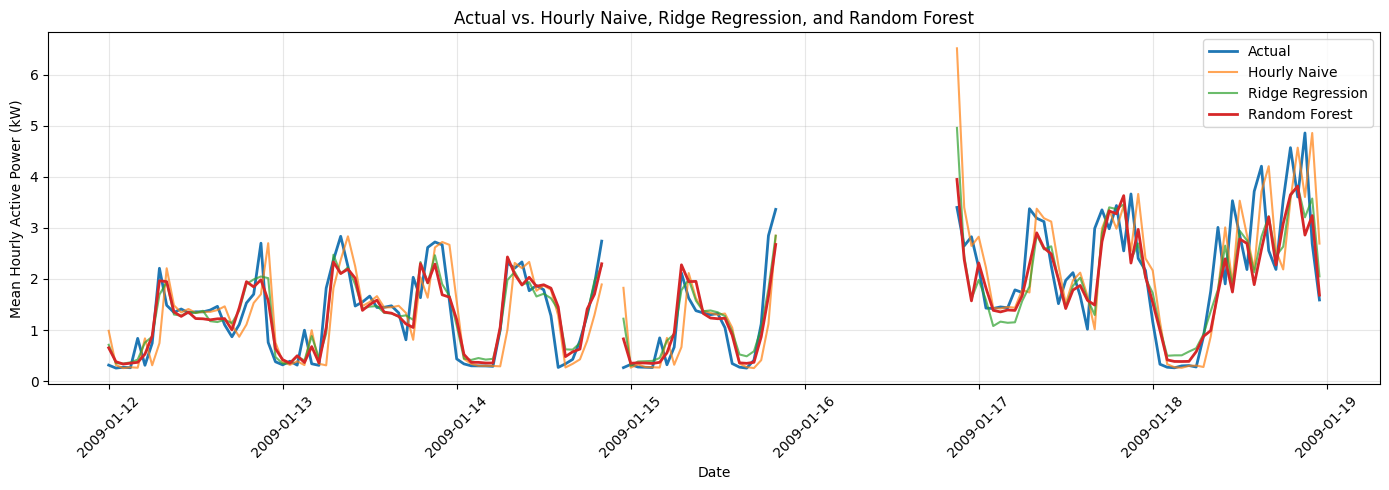

In [13]:
sample = comparison.loc["2009-01-12":"2009-01-18"]

sample = sample.asfreq("h")

plt.figure(figsize=(14, 5))

plt.plot(sample.index, sample["target_kw"], label="Actual", linewidth=2)

plt.plot(sample.index, sample["lag_1"], label="Hourly Naive", alpha=0.7)

plt.plot(sample.index, sample["ridge"], label="Ridge Regression", alpha=0.7)

plt.plot(sample.index, sample["random_forest"], label="Random Forest", linewidth=2)

plt.title("Actual vs. Hourly Naive, Ridge Regression, and Random Forest")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
rf_error = (
    comparison["target_kw"] - comparison["random_forest"]
).abs()

hourly_error = (
    comparison["target_kw"] - comparison["lag_1"]
).abs()

rf_win_rate = (rf_error < hourly_error).mean()

print(f"Random Forest win rate: {rf_win_rate:.2%}")

Random Forest win rate: 52.09%


In [15]:
hourly_errors = comparison.copy()

hourly_errors["hour"] = hourly_errors.index.hour

hourly_errors["rf_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["random_forest"]
).abs()

hourly_errors["ridge_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["ridge"]
).abs()

hourly_errors["hourly_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_1"]
).abs()

hourly_errors["daily_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_24"]
).abs()

hourly_errors["weekly_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_168"]
).abs()

In [16]:
error_by_hour = hourly_errors.groupby("hour")[
    [
        "rf_error",
        "ridge_error",
        "hourly_error",
        "daily_error",
        "weekly_error"
    ]
].mean()

error_by_hour

,rf_error,ridge_error,hourly_error,daily_error,weekly_error
hour,,,,,
0,0.269459,0.252097,0.341994,0.418389,0.348756
1,0.188160,0.179374,0.178609,0.312050,0.297032
2,0.140929,0.150059,0.138851,0.245778,0.233540
3,0.135729,0.145714,0.123845,0.217616,0.224962
4,0.166786,0.174665,0.164672,0.230513,0.250612
5,0.178421,0.192854,0.186459,0.240556,0.251770
6,0.312841,0.313075,0.439315,0.423781,0.409757
7,0.408642,0.498139,0.830938,0.710324,0.591540
8,0.383407,0.379826,0.490877,0.577303,0.555871


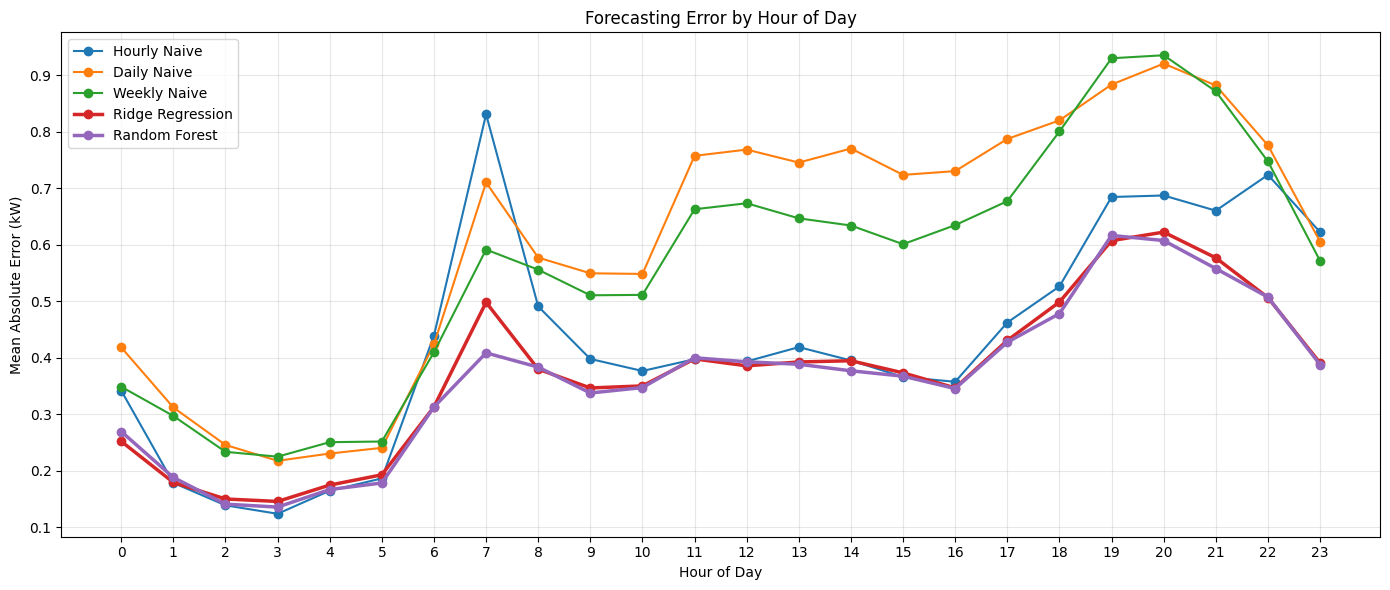

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(
    error_by_hour.index,
    error_by_hour["hourly_error"],
    marker="o",
    label="Hourly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["daily_error"],
    marker="o",
    label="Daily Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["weekly_error"],
    marker="o",
    label="Weekly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["ridge_error"],
    marker="o",
    linewidth=2.5,
    label="Ridge Regression"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["rf_error"],
    marker="o",
    linewidth=2.5,
    label="Random Forest"
)

plt.title("Forecasting Error by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
weekday_errors = hourly_errors.copy()

weekday_errors["day_of_week"] = (
    weekday_errors.index.dayofweek
)

weekday_errors["is_weekend"] = (
    weekday_errors["day_of_week"] >= 5
)

weekday_errors.head()

,target_kw,lag_1,lag_24,lag_168,ridge,random_forest,hour,rf_error,ridge_error,hourly_error,daily_error,weekly_error,day_of_week,is_weekend
timestamp,,,,,,,,,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0.561962,0.751839,0,0.216906,0.027029,0.040500,0.267367,1.307633,3,False
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,0.523083,0.607550,1,0.067084,0.017383,0.005533,0.289867,0.333300,3,False
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,0.526744,0.527816,2,0.047551,0.048622,0.034900,0.284467,0.307533,3,False
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,0.559610,0.531140,3,0.004640,0.033110,0.048867,0.262533,0.255333,3,False
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,0.585761,0.612268,4,0.090368,0.063861,0.004600,0.296633,0.230167,3,False


In [19]:
error_by_day_type = weekday_errors.groupby(
    ["is_weekend", "hour"]
)[
    [
        "hourly_error",
        "daily_error",
        "weekly_error",
        "ridge_error",
        "rf_error"
    ]
].mean()

error_by_day_type

hourly_error  daily_error  weekly_error  ridge_error  \
is_weekend hour                                                         
False      0         0.330613     0.358161      0.258398     0.232704   
           1         0.142655     0.257321      0.205111     0.146559   
           2         0.114893     0.215748      0.177456     0.136395   
           3         0.116166     0.189126      0.189529     0.135580   
           4         0.168025     0.214527      0.229768     0.175139   
           5         0.190838     0.219425      0.213619     0.189691   
           6         0.531572     0.422317      0.452477     0.346705   
           7         0.917641     0.672725      0.579702     0.472196   
           8         0.498061     0.552205      0.521887     0.371675   
           9         0.352135     0.555996      0.462578     0.304236   
           10        0.316024     0.539214      0.465480     0.296503   
           11        0.303800     0.661317      0.532764     0.309240   
           12        0.319607     0.728371      0.595766     0.338376   
           13        0.337636     0.709391      0.606527     0.333926   
           14        0.297174     0.735685      0.551645     0.303480   
           15        0.320746     0.632609      0.513754     0.325637   
           16        0.280880     0.651517      0.508011     0.279981   
           17        0.369977     0.692855      0.502634     0.351904   
           18        0.477397     0.745994      0.685369     0.442496   
           19        0.711476     0.869734      0.890891     0.595731   
           20        0.690242     0.876260      0.894847     0.620943   
           21        0.678454     0.792669      0.773311     0.568768   
           22        0.716286     0.691057      0.658004     0.474481   
           23        0.632713     0.477215      0.502703     0.378775   
True       0         0.370623     0.569891      0.576049     0.300880   
           1         0.269051     0.449717      0.528257     0.261919   
           2         0.199118     0.321318      0.374616     0.184432   
           3         0.143162     0.289280      0.314092     0.171206   
           4         0.156309     0.270396      0.302613     0.173482   
           5         0.175624     0.292840      0.346165     0.200679   
           6         0.210100     0.427418      0.303615     0.229521   
           7         0.614627     0.804128      0.621075     0.562860   
           8         0.473429     0.638257      0.638404     0.399622   
           9         0.513961     0.533140      0.632373     0.453943   
           10        0.528810     0.571355      0.626449     0.485022   
           11        0.631245     0.997242      0.987524     0.619556   
           12        0.578704     0.868862      0.868090     0.504366   
           13        0.622296     0.835989      0.747647     0.539528   
           14        0.640939     0.857271      0.840668     0.623399   
           15        0.481985     0.956676      0.824313     0.495264   
           16        0.554739     0.933566      0.961172     0.518340   
           17        0.703847     1.034135      1.133309     0.636636   
           18        0.655846     1.016621      1.105507     0.647394   
           19        0.616724     0.918425      1.029076     0.636444   
           20        0.679836     1.030135      1.035683     0.626122   
           21        0.616134     1.100871      1.112165     0.596659   
           22        0.741922     0.985073      0.967632     0.585395   
           23        0.597020     0.925344      0.743485     0.420512   

                 rf_error  
is_weekend hour            
False      0     0.250601  
           1     0.156145  
           2     0.124224  
           3     0.124711  
           4     0.168759  
           5     0.177312  
           6     0.335762  
           7     0.379674  
           8     0.378472  
           9     0.298456  
           10    0.297606  
  

In [20]:
weekday_profile = error_by_day_type.loc[False]

weekend_profile = error_by_day_type.loc[True]

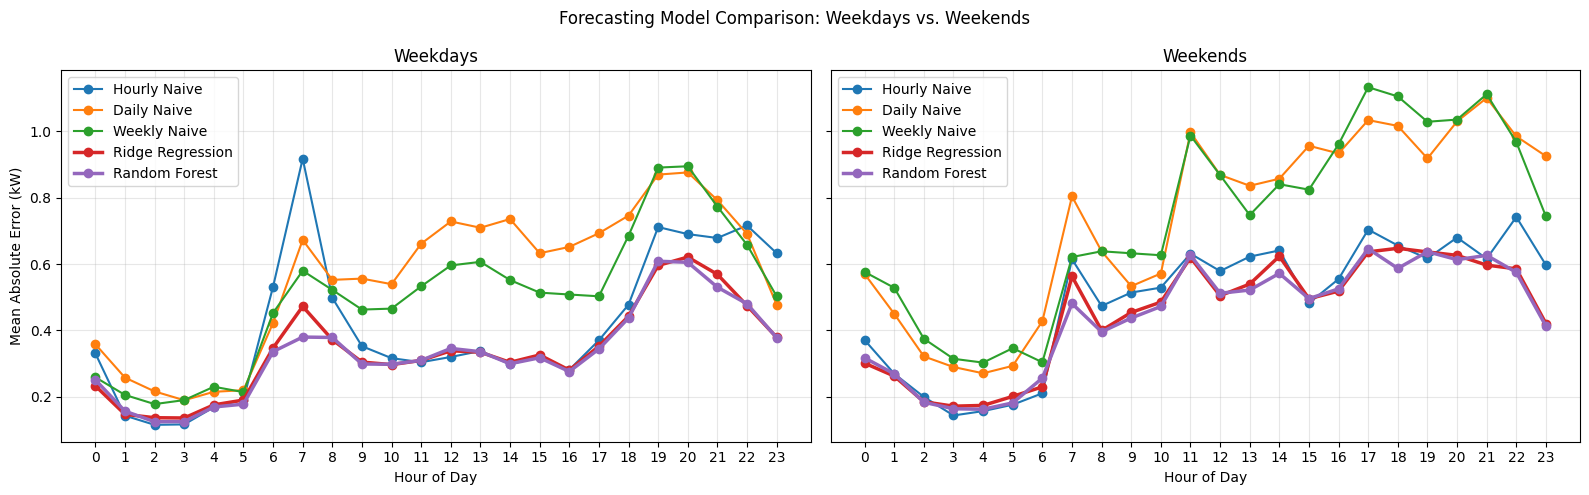

In [21]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, profile, title in [
    (axes[0], weekday_profile, "Weekdays"),
    (axes[1], weekend_profile, "Weekends")
]:
    ax.plot(
        profile.index,
        profile["hourly_error"],
        marker="o",
        label="Hourly Naive"
    )

    ax.plot(
        profile.index,
        profile["daily_error"],
        marker="o",
        label="Daily Naive"
    )

    ax.plot(
        profile.index,
        profile["weekly_error"],
        marker="o",
        label="Weekly Naive"
    )

    ax.plot(
        profile.index,
        profile["ridge_error"],
        marker="o",
        linewidth=2.5,
        label="Ridge Regression"
    )

    ax.plot(
        profile.index,
        profile["rf_error"],
        marker="o",
        linewidth=2.5,
        label="Random Forest"
    )

    ax.set_title(title)
    ax.set_xlabel("Hour of Day")
    ax.set_xticks(range(24))
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Mean Absolute Error (kW)")

fig.suptitle(
    "Forecasting Model Comparison: Weekdays vs. Weekends"
)

plt.tight_layout()
plt.show()

In [22]:
error_by_day_type.loc[
    [(False, 7), (True, 7)],
    ["rf_error", "ridge_error", "hourly_error", "weekly_error"]
]

,,rf_error,ridge_error,hourly_error,weekly_error
is_weekend,hour,,,,
False,7,0.379674,0.472196,0.917641,0.579702
True,7,0.480911,0.562860,0.614627,0.621075


In [23]:
print("Raw RF MAE:",
      mean_absolute_error(y_val, rf_predictions_raw))

print("Clipped RF MAE:",
      mean_absolute_error(y_val, rf_predictions))

print("Raw RF RMSE:",
      np.sqrt(mean_squared_error(y_val, rf_predictions_raw)))

print("Clipped RF RMSE:",
      np.sqrt(mean_squared_error(y_val, rf_predictions)))

Raw RF MAE: 0.36323508606262617
Clipped RF MAE: 0.36323508606262617
Raw RF RMSE: 0.5289228980888748
Clipped RF RMSE: 0.5289228980888748


In [24]:
peak_analysis = comparison.copy()

# Calculate signed residuals
peak_analysis["rf_residual"] = (
    peak_analysis["target_kw"] -
    peak_analysis["random_forest"]
)

# Select the 10 highest actual demand observations
top_10_peaks = peak_analysis.nlargest(
    10, "target_kw"
)

top_10_peaks[
    [
        "target_kw",
        "random_forest",
        "lag_1",
        "lag_24",
        "lag_168",
        "ridge",
        "rf_residual"
    ]
]

,target_kw,random_forest,lag_1,lag_24,lag_168,ridge,rf_residual
timestamp,,,,,,,
2009-02-11 18:00:00,5.233800,1.278661,1.013400,1.303867,2.542400,1.409692,3.955139
2009-04-12 21:00:00,5.133967,3.250222,5.098300,2.738933,1.259500,3.807736,1.883744
2009-11-22 20:00:00,5.115167,3.309087,3.818933,3.538233,2.040500,3.370972,1.806080
2009-04-12 20:00:00,5.098300,2.501632,2.653167,4.145133,2.183467,2.652599,2.596668
2009-01-24 11:00:00,5.073400,1.731089,1.861733,1.592900,1.516567,1.828355,3.342311
2009-01-31 17:00:00,5.072500,2.986026,3.407433,3.019767,1.065167,2.899238,2.086474
2009-01-18 21:00:00,4.860700,2.860566,3.606900,3.665800,3.503933,3.208421,2.000134
2009-11-03 20:00:00,4.830833,3.119030,4.125833,2.753667,2.055633,3.507037,1.711804
2009-02-22 17:00:00,4.829433,2.723945,3.718800,0.506933,0.357133,2.852971,2.105488


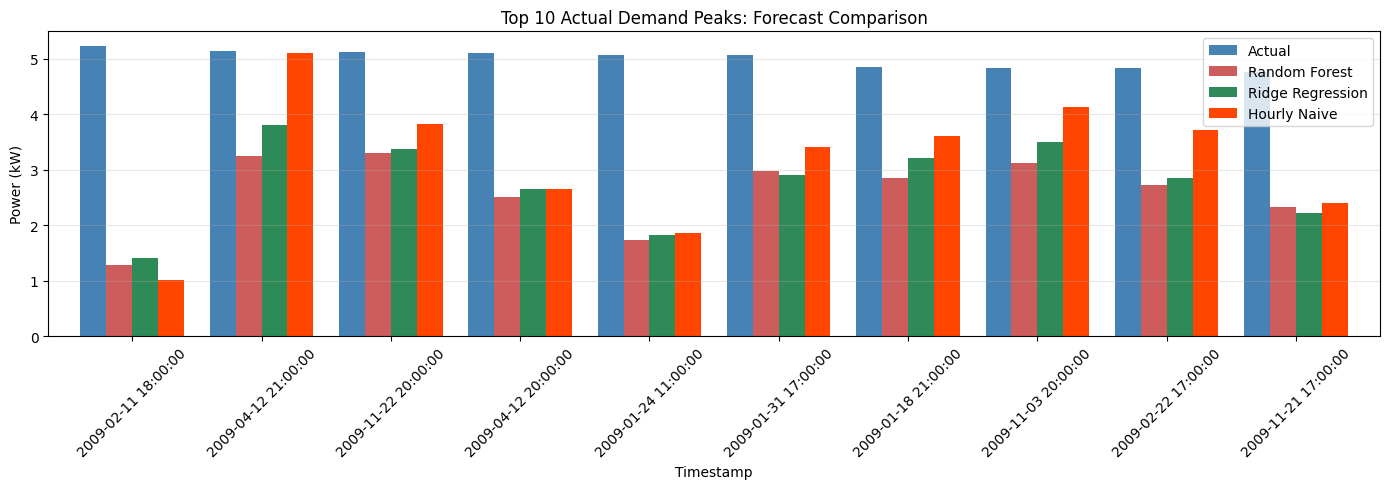

In [25]:
top_10_peaks[
    ["target_kw", "random_forest", "ridge", "lag_1"]
].plot(
    kind="bar",
    figsize=(14, 5),
    width=0.8,
    color=["steelblue", "indianred", "seagreen", "orangered"],
)

plt.title("Top 10 Actual Demand Peaks: Forecast Comparison")
plt.xlabel("Timestamp")
plt.ylabel("Power (kW)")
plt.legend(["Actual", "Random Forest", "Ridge Regression", "Hourly Naive"])
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
peak_results = []

for model in ["random_forest", "ridge", "lag_1", "lag_24", "lag_168"]:

    actual = top_10_peaks["target_kw"]
    predicted = top_10_peaks[model]

    residuals = actual - predicted

    peak_results.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Mean Residual": residuals.mean(),
        "Underpredicted Peaks": (residuals > 0).sum()
    })

peak_results_df = pd.DataFrame(peak_results)

peak_results_df.sort_values("MAE")

,Model,MAE,RMSE,Mean Residual,Underpredicted Peaks
2,lag_1,1.830477,2.178000,1.830477,10
1,ridge,2.225080,2.355818,2.225080,10
0,random_forest,2.392557,2.490523,2.392557,10
3,lag_24,2.571140,2.814814,2.571140,10
4,lag_168,3.050600,3.188024,3.050600,10


In [27]:
# Find the 95th percentile of actual demand
peak_threshold = peak_analysis["target_kw"].quantile(0.95)

# Select high-demand observations
high_demand = peak_analysis[
    peak_analysis["target_kw"] >= peak_threshold
].copy()

print("High-demand threshold:", peak_threshold)
print("High-demand observations:", len(high_demand))
print("Total validation observations:", len(peak_analysis))

High-demand threshold: 2.737089999999999
High-demand observations: 407
Total validation observations: 8124


In [28]:
high_demand_results = []

for model in ["random_forest", "ridge", "lag_1", "lag_24", "lag_168"]:

    actual = high_demand["target_kw"]
    predicted = high_demand[model]

    residuals = actual - predicted

    high_demand_results.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Mean Residual": residuals.mean(),
        "Underprediction Rate (%)": (
            (residuals > 0).mean() * 100
        )
    })

high_demand_results_df = pd.DataFrame(
    high_demand_results
)

high_demand_results_df.sort_values("MAE")

,Model,MAE,RMSE,Mean Residual,Underprediction Rate (%)
1,ridge,1.105884,1.308388,1.025973,89.680590
0,random_forest,1.112966,1.317644,1.049540,90.909091
2,lag_1,1.139414,1.379434,0.871905,78.869779
4,lag_168,1.560551,1.842291,1.384659,88.452088
3,lag_24,1.634815,1.904740,1.511210,90.909091


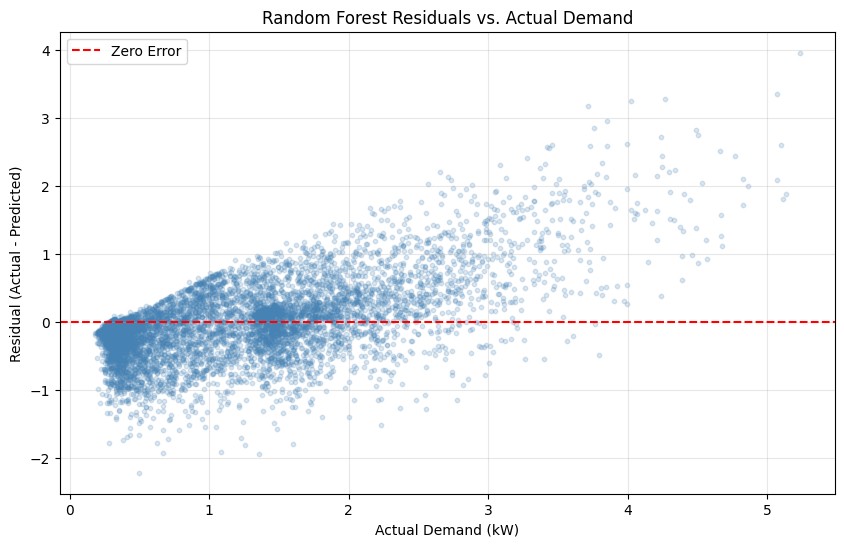

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    peak_analysis["target_kw"],
    peak_analysis["rf_residual"],
    alpha=0.2,
    s=10,
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Actual Demand (kW)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residuals vs. Actual Demand")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [30]:
peak_analysis["demand_group"] = pd.qcut(
    peak_analysis["target_kw"],
    q=5,
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

residual_summary = (
    peak_analysis
    .groupby("demand_group", observed=True)
    .agg(
        observations=("target_kw", "size"),
        mean_actual=("target_kw", "mean"),
        mean_predicted=("random_forest", "mean"),
        mean_residual=("rf_residual", "mean")
    )
)

residual_summary

,observations,mean_actual,mean_predicted,mean_residual
demand_group,,,,
Very Low,1625,0.295046,0.488300,-0.193254
Low,1625,0.402821,0.662003,-0.259182
Medium,1624,0.835857,0.995531,-0.159674
High,1626,1.458611,1.467615,-0.009004
Very High,1624,2.425284,1.935371,0.489912


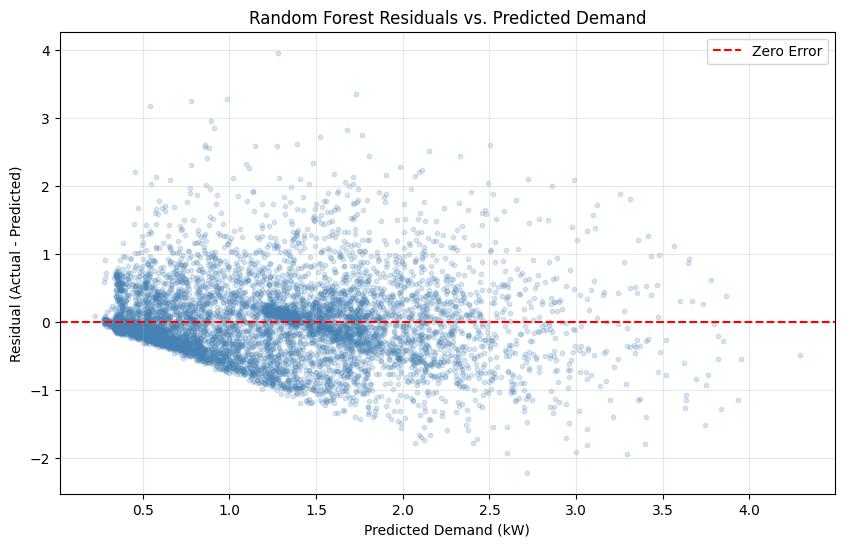

Overall mean residual: -0.026285268479802858


In [31]:
plt.figure(figsize=(10, 6))

plt.scatter(
    peak_analysis["random_forest"],
    peak_analysis["rf_residual"],
    alpha=0.2,
    s=10,
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Predicted Demand (kW)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residuals vs. Predicted Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Overall mean residual:",
    peak_analysis["rf_residual"].mean()
)

## E05 — Recent Rolling Average

Hypothesis: Incorporating the most recent 24 hours of electricity
demand may improve one-hour-ahead forecasting accuracy by giving
the model more information about current consumption patterns.

In [32]:
experiment_columns = baseline_columns + [
    "rolling_mean_24_recent"
]

experiment_df = features[
    experiment_columns
].dropna().copy()

experiment_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 30316 entries, 2006-12-23 18:00:00 to 2010-11-26 20:00:00
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   target_kw               30316 non-null  float64
 1   hour                    30316 non-null  int32  
 2   day_of_week             30316 non-null  int32  
 3   month                   30316 non-null  int32  
 4   is_weekend              30316 non-null  int64  
 5   lag_1                   30316 non-null  float64
 6   lag_24                  30316 non-null  float64
 7   lag_168                 30316 non-null  float64
 8   rolling_mean_24         30316 non-null  float64
 9   rolling_mean_24_recent  30316 non-null  float64
dtypes: float64(6), int32(3), int64(1)
memory usage: 2.2 MB


In [33]:
print("Original dataset:", model_df.shape)
print("Experiment dataset:", experiment_df.shape)

experiment_df.tail()

Original dataset: (31611, 9)
Experiment dataset: (30316, 10)


,target_kw,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_24_recent
timestamp,,,,,,,,,,
2010-11-26 16:00:00,1.067933,16,4,11,0,0.876433,0.541800,1.469700,0.949582,1.221832
2010-11-26 17:00:00,1.725900,17,4,11,0,1.067933,1.480100,0.824267,0.930464,1.243754
2010-11-26 18:00:00,1.573467,18,4,11,0,1.725900,2.211600,1.018467,0.936733,1.253996
2010-11-26 19:00:00,1.659333,19,4,11,0,1.573467,2.330467,1.249767,0.971410,1.227407
2010-11-26 20:00:00,1.163700,20,4,11,0,1.659333,1.647833,1.665267,0.943700,1.199443


In [34]:
experiment_train = experiment_df.loc[
    :"2008-12-31"
].copy()

experiment_val = experiment_df.loc[
    "2009-01-01":"2009-12-31"
].copy()

print("Experiment training:", experiment_train.shape)
print("Experiment validation:", experiment_val.shape)

Experiment training: (15888, 10)
Experiment validation: (7787, 10)


In [35]:
y_train_exp = experiment_train["target_kw"]

y_val_exp = experiment_val["target_kw"]

In [36]:
X_train_exp = experiment_train.drop(
    columns=["target_kw"]
)

X_val_exp = experiment_val.drop(
    columns=["target_kw"]
)

X_train_exp.head()

,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_24_recent
timestamp,,,,,,,,,
2006-12-23 18:00:00,18,5,12,1,5.452533,2.686967,3.632200,1.153442,3.099713
2006-12-23 19:00:00,19,5,12,1,3.879400,3.938167,3.400233,1.225985,3.149397
2006-12-23 20:00:00,20,5,12,1,4.117833,3.536067,3.268567,1.271764,3.156883
2006-12-23 21:00:00,21,5,12,1,4.181400,4.548667,3.056467,1.420364,3.183772
2006-12-23 22:00:00,22,5,12,1,3.288433,3.065067,2.200133,1.536397,3.131263


## # E05-A — Original rolling average (control)

In [37]:
X_train_a = X_train_exp.drop(
    columns=["rolling_mean_24_recent"]
)

X_val_a = X_val_exp.drop(
    columns=["rolling_mean_24_recent"]
)

## Apply existing calendar encoding

In [38]:
X_train_a_encoded = encode_calendar(X_train_a)

X_val_a_encoded = encode_calendar(X_val_a)

## Train our control model

In [39]:
rf_a = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2
)

rf_a.fit(X_train_a_encoded, y_train_exp)

predictions_a = rf_a.predict(X_val_a_encoded)

## Evaluate

In [40]:
mae_a = mean_absolute_error(
    y_val_exp, predictions_a
)

rmse_a = np.sqrt(
    mean_squared_error(y_val_exp, predictions_a)
)

print("E05-A MAE:", mae_a)
print("E05-A RMSE:", rmse_a)

E05-A MAE: 0.36440196062320335
E05-A RMSE: 0.5308367777534785


## E05-B: Recent Rolling Average

In [41]:
X_train_b = X_train_exp.drop(
    columns=["rolling_mean_24"]
)

X_val_b = X_val_exp.drop(
    columns=["rolling_mean_24"]
)

In [42]:
X_train_b_encoded = encode_calendar(X_train_b)

X_val_b_encoded = encode_calendar(X_val_b)

## Train the model

In [43]:
rf_b = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2
)

rf_b.fit(X_train_b_encoded, y_train_exp)

predictions_b = rf_b.predict(X_val_b_encoded)

## Evaluate

In [44]:
mae_b = mean_absolute_error(
    y_val_exp, predictions_b
)

rmse_b = np.sqrt(
    mean_squared_error(y_val_exp, predictions_b)
)

print("E05-B MAE:", mae_b)
print("E05-B RMSE:", rmse_b)

E05-B MAE: 0.3636634990059469
E05-B RMSE: 0.5303717943403119


## E05-C — Both rolling averages


In [45]:
X_train_c = X_train_exp.copy()

X_val_c = X_val_exp.copy()

In [46]:
X_train_c_encoded = encode_calendar(X_train_c)

X_val_c_encoded = encode_calendar(X_val_c)

In [47]:
rf_c = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2
)

rf_c.fit(X_train_c_encoded, y_train_exp)

predictions_c = rf_c.predict(X_val_c_encoded)

In [48]:
mae_c = mean_absolute_error(
    y_val_exp, predictions_c
)

rmse_c = np.sqrt(
    mean_squared_error(y_val_exp, predictions_c)
)

print("E05-C MAE:", mae_c)
print("E05-C RMSE:", rmse_c)

E05-C MAE: 0.363423971573006
E05-C RMSE: 0.529835307117737


## E05 — Compare model predictions

In [49]:
comparison_exp = experiment_val[
    ["target_kw", "lag_1", "lag_24", "lag_168"]
].copy()

comparison_exp["rf_a"] = predictions_a
comparison_exp["rf_b"] = predictions_b
comparison_exp["rf_c"] = predictions_c

comparison_exp["ridge"] = comparison[
    "ridge"
].reindex(comparison_exp.index)

comparison_exp.head()

,target_kw,lag_1,lag_24,lag_168,rf_a,rf_b,rf_c,ridge
timestamp,,,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0.727477,0.669661,0.719137,0.561962
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,0.596042,0.605752,0.598116,0.523083
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,0.527116,0.522951,0.521762,0.526744
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,0.531590,0.525687,0.525525,0.559610
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,0.608854,0.579773,0.584606,0.585761


In [50]:
comparison_exp["rf_a_residual"] = (
    comparison_exp["target_kw"] -
    comparison_exp["rf_a"]
)

comparison_exp["rf_b_residual"] = (
    comparison_exp["target_kw"] -
    comparison_exp["rf_b"]
)

comparison_exp["rf_c_residual"] = (
    comparison_exp["target_kw"] -
    comparison_exp["rf_c"]
)

comparison_exp.head()

,target_kw,lag_1,lag_24,lag_168,rf_a,rf_b,rf_c,ridge,rf_a_residual,rf_b_residual,rf_c_residual
timestamp,,,,,,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0.727477,0.669661,0.719137,0.561962,-0.192544,-0.134728,-0.184204
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,0.596042,0.605752,0.598116,0.523083,-0.055576,-0.065285,-0.057649
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,0.527116,0.522951,0.521762,0.526744,0.048251,0.052416,0.053605
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,0.531590,0.525687,0.525525,0.559610,-0.005090,0.000813,0.000975
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,0.608854,0.579773,0.584606,0.585761,-0.086954,-0.057873,-0.062706


## E05 — High-demand analysis

In [51]:
high_demand_threshold_exp = (
    comparison_exp["target_kw"].quantile(0.95)
)

high_demand_exp = comparison_exp[
    comparison_exp["target_kw"] >= high_demand_threshold_exp
].copy()

print("High-demand threshold:", high_demand_threshold_exp)
print("High-demand observations:", len(high_demand_exp))
print("Total validation observations:", len(comparison_exp))

High-demand threshold: 2.73758
High-demand observations: 390
Total validation observations: 7787


In [52]:
high_demand_results_exp = []

for model in [
    "rf_a",
    "rf_b",
    "rf_c",
    "ridge",
    "lag_1",
    "lag_24",
    "lag_168"
]:
    actual = high_demand_exp["target_kw"]
    predicted = high_demand_exp[model]

    residual = actual - predicted

    high_demand_results_exp.append({
        "Model": model,
        "MAE": mean_absolute_error(
            actual, predicted
        ),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Mean Residual": residual.mean(),
        "Underprediction Rate (%)": (
            (residual > 0).mean() * 100
        )
    })

high_demand_results_exp_df = pd.DataFrame(
    high_demand_results_exp
)

high_demand_results_exp_df.sort_values("MAE")

,Model,MAE,RMSE,Mean Residual,Underprediction Rate (%)
1,rf_b,1.103409,1.316183,1.045677,91.282051
3,ridge,1.105974,1.311942,1.024707,89.743590
2,rf_c,1.108216,1.317870,1.054768,91.282051
0,rf_a,1.110474,1.319125,1.048854,91.025641
4,lag_1,1.136544,1.377570,0.861632,78.717949
6,lag_168,1.580572,1.860126,1.406933,88.717949
5,lag_24,1.638781,1.913986,1.534504,91.282051


## E06 — Three-hour rolling mean

In [53]:
e06_columns = baseline_columns + [
    "rolling_mean_3"
]

e06_df = features[e06_columns].dropna().copy()

print("E06 dataset:", e06_df.shape)

e06_df.tail(10)

E06 dataset: (31490, 10)


,target_kw,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_3
timestamp,,,,,,,,,,
2010-11-26 11:00:00,1.338900,11,4,11,0,1.352767,1.028067,1.395467,1.195717,1.734011
2010-11-26 12:00:00,1.490200,12,4,11,0,1.338900,0.499733,1.390700,1.150549,1.513878
2010-11-26 13:00:00,1.612933,13,4,11,0,1.490200,0.356233,1.594400,1.083682,1.393956
2010-11-26 14:00:00,1.407767,14,4,11,0,1.612933,0.300667,1.521100,1.012136,1.480678
2010-11-26 15:00:00,0.876433,15,4,11,0,1.407767,0.333000,1.622867,0.963426,1.503633
2010-11-26 16:00:00,1.067933,16,4,11,0,0.876433,0.541800,1.469700,0.949582,1.299044
2010-11-26 17:00:00,1.725900,17,4,11,0,1.067933,1.480100,0.824267,0.930464,1.117378
2010-11-26 18:00:00,1.573467,18,4,11,0,1.725900,2.211600,1.018467,0.936733,1.223422
2010-11-26 19:00:00,1.659333,19,4,11,0,1.573467,2.330467,1.249767,0.971410,1.455767


In [54]:
e06_train = e06_df.loc[:"2008-12-31 23:00"].copy()

e06_val = e06_df.loc[
    "2009-01-01":"2009-12-31 23:00"
].copy()

print("Training:", e06_train.shape)
print("Validation:", e06_val.shape)

Training: (16557, 10)
Validation: (8092, 10)


In [55]:
y_train_e06 = e06_train["target_kw"]
y_val_e06 = e06_val["target_kw"]

X_train_e06 = e06_train.drop(columns=["target_kw"])
X_val_e06 = e06_val.drop(columns=["target_kw"])

In [56]:
X_train_e06_a = X_train_e06.drop(
    columns=["rolling_mean_3"]
)

X_val_e06_a = X_val_e06.drop(
    columns=["rolling_mean_3"]
)

In [57]:
X_train_e06_b = X_train_e06.copy()

X_val_e06_b = X_val_e06.copy()

## Encode control features

In [58]:
X_train_e06_a_encoded = encode_calendar(
    X_train_e06_a
)

X_val_e06_a_encoded = encode_calendar(
    X_val_e06_a
)

## Encode experimental features

In [59]:
X_train_e06_b_encoded = encode_calendar(
    X_train_e06_b
)

X_val_e06_b_encoded = encode_calendar(
    X_val_e06_b
)

## Train the control model

In [60]:
rf_e06_a = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2
)

rf_e06_a.fit(
    X_train_e06_a_encoded,
    y_train_e06
)

predictions_e06_a = rf_e06_a.predict(
    X_val_e06_a_encoded
)

## Train the experimental model

In [61]:
rf_e06_b = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2
)

rf_e06_b.fit(
    X_train_e06_b_encoded,
    y_train_e06
)

predictions_e06_b = rf_e06_b.predict(
    X_val_e06_b_encoded
)

## Evaluate our results

In [62]:
mae_e06_a = mean_absolute_error(
    y_val_e06, predictions_e06_a
)

rmse_e06_a = np.sqrt(
    mean_squared_error(y_val_e06, predictions_e06_a)
)

mae_e06_b = mean_absolute_error(
    y_val_e06, predictions_e06_b
)

rmse_e06_b = np.sqrt(
    mean_squared_error(y_val_e06, predictions_e06_b)
)

print("E06-A MAE:", mae_e06_a)
print("E06-A RMSE:", rmse_e06_a)

print("E06-B MAE:", mae_e06_b)
print("E06-B RMSE:", rmse_e06_b)

E06-A MAE: 0.36200549546117
E06-A RMSE: 0.5275122432196986
E06-B MAE: 0.3591801704217219
E06-B RMSE: 0.5239984591929949


## Prediction comparison

In [63]:
comparison_e06 = e06_val[
    ["target_kw", "lag_1", "lag_24", "lag_168"]
].copy()

comparison_e06["rf_a"] = predictions_e06_a
comparison_e06["rf_b"] = predictions_e06_b

comparison_e06.head()

,target_kw,lag_1,lag_24,lag_168,rf_a,rf_b
timestamp,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0.726154,0.702030
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,0.605305,0.623915
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,0.530384,0.543496
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,0.535214,0.552253
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,0.597800,0.633352


### Top 5% of actual demand

In [64]:
threshold_e06 = comparison_e06["target_kw"].quantile(0.95)

high_demand_e06 = comparison_e06[
    comparison_e06["target_kw"] >= threshold_e06
].copy()

print("Threshold:", threshold_e06)
print("High-demand observations:", len(high_demand_e06))

Threshold: 2.7338766666666663
High-demand observations: 405


In [65]:
high_demand_results_e06 = []

for model in ["rf_a", "rf_b", "lag_1"]:
    actual = high_demand_e06["target_kw"]
    predicted = high_demand_e06[model]

    residual = actual - predicted

    high_demand_results_e06.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Mean Residual": residual.mean(),
        "Underprediction Rate (%)": (residual > 0).mean() * 100
    })

pd.DataFrame(high_demand_results_e06).sort_values("MAE")

,Model,MAE,RMSE,Mean Residual,Underprediction Rate (%)
1,rf_b,1.096234,1.305319,1.032674,90.864198
0,rf_a,1.102023,1.310357,1.031895,90.123457
2,lag_1,1.135787,1.375485,0.862717,78.518519


## E07: Hourly demand change

NameError: name 'power' is not defined